# 01.P · The ShopWave sales report: solution

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/01-working-with-data/project/solution.ipynb)

One worked answer. Yours may differ where your cleaning decisions differ; that is fine if you wrote them down.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()

(541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Clean the data

*Intent: remove rows that are not sales, keep a record of what was removed and why.*

| Rule | Reason |
|---|---|
| Drop invoices starting with `C` | Cancellations; the matching sale is also in the data, so the cancellation would double-count in reverse |
| Drop `Quantity <= 0` | Returns and stock adjustments, not sales |
| Drop `Price <= 0` | Free items, damaged stock, bookkeeping lines |
| Drop exact duplicates | Export artefact |
| Keep guest checkouts (missing `Customer ID`) **for revenue**, drop them **for customer analysis** | Their money is real; their identity is not |

In [3]:
before = len(raw)
sales_all = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales_all = sales_all[(sales_all["Quantity"] > 0) & (sales_all["Price"] > 0)].drop_duplicates()
sales_all["Revenue"] = sales_all["Quantity"] * sales_all["Price"]

sales = sales_all.dropna(subset=["Customer ID"]).copy()
sales["Customer ID"] = sales["Customer ID"].astype(int)

guest_rev = sales_all.loc[sales_all["Customer ID"].isna(), "Revenue"].sum()
print(f"rows: {before:,} raw → {len(sales_all):,} valid sales → {len(sales):,} with a customer ID")
print(f"total revenue (all valid sales): £{sales_all['Revenue'].sum():,.0f}")
print(f"of which guest checkouts:        £{guest_rev:,.0f}  ({guest_rev / sales_all['Revenue'].sum():.1%})")

rows: 541,910 raw → 524,879 valid sales → 392,693 with a customer ID
total revenue (all valid sales): £10,642,129
of which guest checkouts:        £1,754,902  (16.5%)


*Finding: about a quarter of rows but a smaller share of revenue come from guests. Revenue figures below use all valid sales; customer figures use identified customers only.*

## 2. Revenue by month

*Intent: see the trend and the seasonality.*

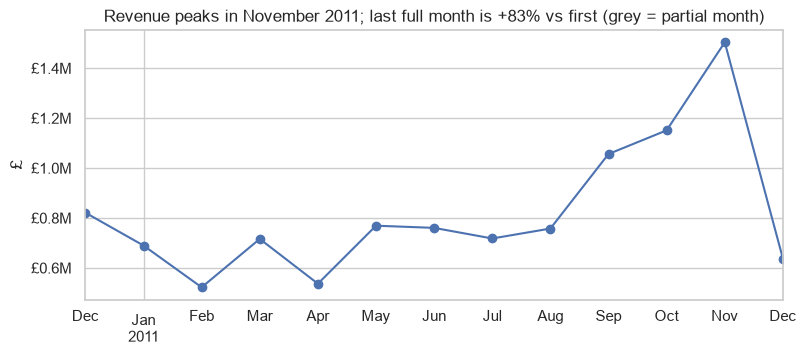

November 2011: £1,503,867  = 15% of the twelve full months


In [4]:
sales_all["month"] = sales_all["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
monthly = sales_all.groupby("month")["Revenue"].sum()
full = monthly.iloc[:-1]                     # December 2011 ends on the 9th
growth = full.iloc[-1] / full.iloc[0] - 1
peak = full.idxmax()

fig, ax = plt.subplots(figsize=(9, 3.5))
monthly.plot(ax=ax, marker="o")
ax.axvspan(monthly.index[-1], monthly.index[-1] + pd.offsets.MonthEnd(1), color="lightgrey", alpha=.5)
ax.set(title=f"Revenue peaks in {peak:%B %Y}; last full month is {growth:+.0%} vs first (grey = partial month)",
       xlabel="", ylabel="£")
ax.yaxis.set_major_formatter(lambda v, _: f"£{v/1e6:.1f}M")
plt.show()
print(f"{peak:%B %Y}: £{full.max():,.0f}  = {full.max()/full.sum():.0%} of the twelve full months")

*Finding: revenue climbs steeply from September and November alone is about 15% of the twelve full months. December 2011 is low only because the data stops on the 9th.*

## 3. Top 10 products

*Intent: what sells. Exclude lines that are not products.*

non-product lines excluded: ['POSTAGE' 'DOTCOM POSTAGE' 'Manual' 'Bank Charges' 'AMAZON FEE' 'SAMPLES']


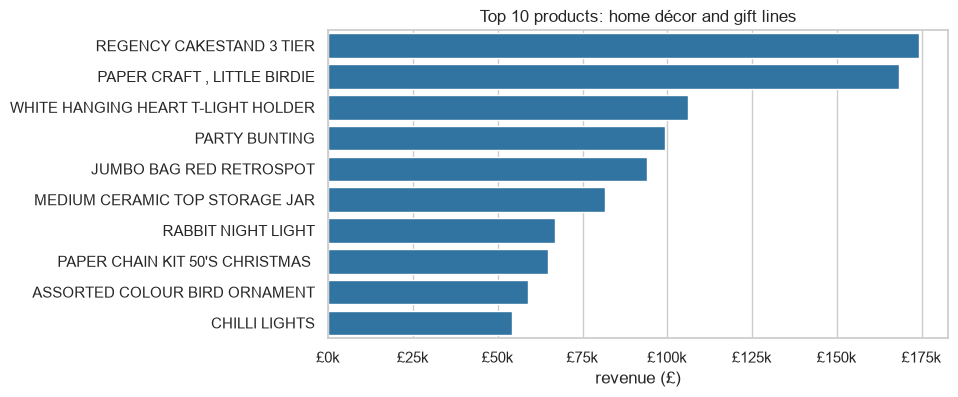

In [5]:
not_products = sales_all["StockCode"].astype(str).str.upper().isin(["POST", "M", "DOT", "BANK CHARGES", "AMAZONFEE", "S", "CRUK", "D"])
print("non-product lines excluded:", sales_all.loc[not_products, "Description"].unique())
prod = (sales_all[~not_products].groupby("Description")["Revenue"].sum()
        .sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=prod.values, y=prod.index, ax=ax, color="tab:blue")
ax.set(title="Top 10 products: home décor and gift lines", xlabel="revenue (£)", ylabel="")
ax.xaxis.set_major_formatter(lambda v, _: f"£{v/1e3:.0f}k")
plt.show()

*Finding: the top product (a paper craft item) is dominated by a single enormous order; the next nine are steady gift and décor lines. POSTAGE and Manual were excluded as non-products.*

## 4. Top countries excluding the UK

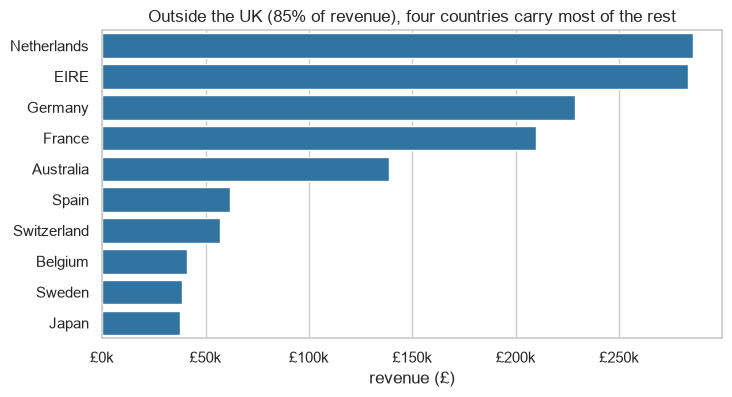

In [6]:
by_country = sales_all.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
uk_share = by_country["United Kingdom"] / by_country.sum()
non_uk = by_country.drop("United Kingdom").head(10)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=non_uk.values, y=non_uk.index, ax=ax, color="tab:blue")
ax.set(title=f"Outside the UK ({uk_share:.0%} of revenue), four countries carry most of the rest", xlabel="revenue (£)", ylabel="")
ax.xaxis.set_major_formatter(lambda v, _: f"£{v/1e3:.0f}k")
plt.show()

In [7]:
per_invoice = sales_all.groupby(["Invoice", "Country"])["Revenue"].sum().reset_index()
aov = per_invoice.groupby("Country")["Revenue"].agg(invoices="size", avg_order="mean", median_order="median")
aov.loc[by_country.index[:6]].round(0)

,invoices,avg_order,median_order
Country,,,
United Kingdom,18019,500.0,300.0
Netherlands,94,3037.0,807.0
EIRE,288,983.0,652.0
Germany,457,500.0,355.0
France,392,535.0,375.0
Australia,57,2429.0,430.0


*Finding: the Netherlands, EIRE, Germany and France are each 2–3% of revenue. The Netherlands and Australia have average orders several times the UK's: a few wholesale accounts, not many consumers.*

## 5. Repeat vs one-time customers

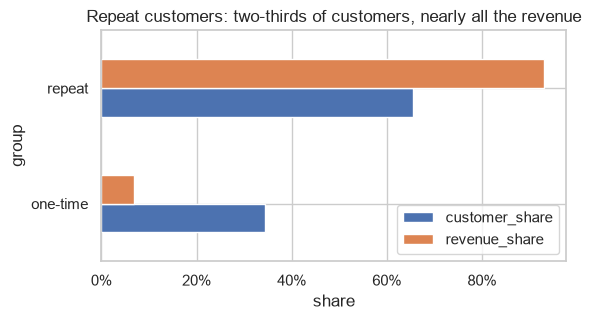

,customers,revenue,customer_share,revenue_share
group,,,,
one-time,1493,613989.56,0.34,0.07
repeat,2845,8273237.33,0.66,0.93


In [8]:
cust = sales.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"))
cust["group"] = np.where(cust["orders"] > 1, "repeat", "one-time")
summary = cust.groupby("group").agg(customers=("spend", "size"), revenue=("spend", "sum"))
summary["customer_share"] = summary["customers"] / summary["customers"].sum()
summary["revenue_share"] = summary["revenue"] / summary["revenue"].sum()

fig, ax = plt.subplots(figsize=(6, 3))
summary[["customer_share", "revenue_share"]].plot.barh(ax=ax)
ax.set(title="Repeat customers: two-thirds of customers, nearly all the revenue", xlabel="share")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.show()
summary.round(2)

*Finding: about 66% of identified customers ordered more than once and they bring roughly 90% of identified revenue. Converting a one-time buyer into a second order is the most valuable thing marketing can do.*

## 6. Weekday × hour

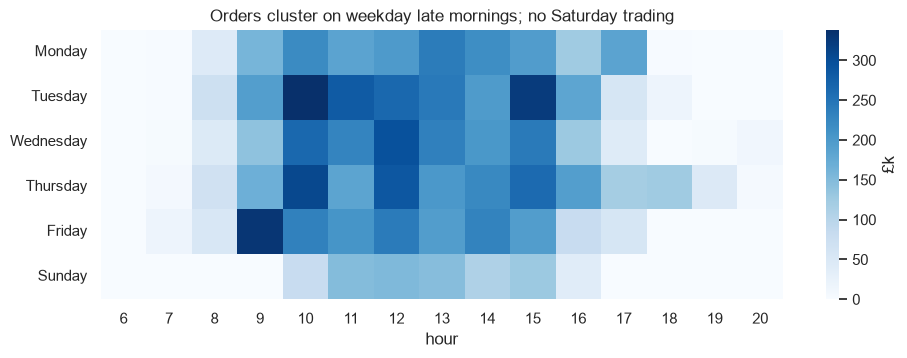

In [9]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
heat = (sales_all.assign(weekday=sales_all["InvoiceDate"].dt.day_name(), hour=sales_all["InvoiceDate"].dt.hour)
                 .pivot_table(index="weekday", columns="hour", values="Revenue", aggfunc="sum", fill_value=0)
                 .reindex(days))
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(heat / 1e3, cmap="Blues", ax=ax, cbar_kws={"label": "£k"})
ax.set(title="Orders cluster on weekday late mornings; no Saturday trading", xlabel="hour", ylabel="")
plt.show()

*Finding: 10:00–15:00 Monday to Thursday carries most of the revenue; Sunday is quiet and Saturday is absent. Staff the support desk for weekday late mornings.*

## 7. Five business insights

1. **November is ~15% of annual revenue and the ramp starts in September.** Begin Christmas stock purchasing and staffing in August; a stock-out in October costs more than any other month.
2. **Repeat customers are ~66% of identified customers but ~90% of their revenue.** A campaign that moves even 10% of one-time buyers to a second order is worth more than any new-customer acquisition of the same size. (Module 03 builds the model that says *which* ones.)
3. **The UK is over 80% of revenue; four countries carry most of the rest.** Netherlands and Australia orders are wholesale-sized. Give those accounts a dedicated contact rather than treating them as consumers.
4. **A quarter of transaction rows are guest checkouts.** Their revenue is real but their behaviour is invisible. A light-touch account prompt at checkout would turn them into analysable, re-targetable customers.
5. **The warehouse ships Monday–Friday with Sunday orders waiting.** Orders cluster 10:00–15:00 on weekdays; support and dispatch should be fully staffed then and can run lighter after 16:00.